In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pickle
import json
import os
import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader

from src.trainer_dann import TrainerLSTM, TrainerDANN
from src.utils import evaluation
from src.config import NATIVE_MODEL_BY_DOMAIN, DEVICE

c:\Users\alice\master_thesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
results_dict = {"frame_bilstm": "outputs/results/frame_bilstm", "frame_dann_bilstm": "outputs/results/frame_dann_bilstm"}
all_reports = {}

Confusion Matrices for frame_bilstm experiment


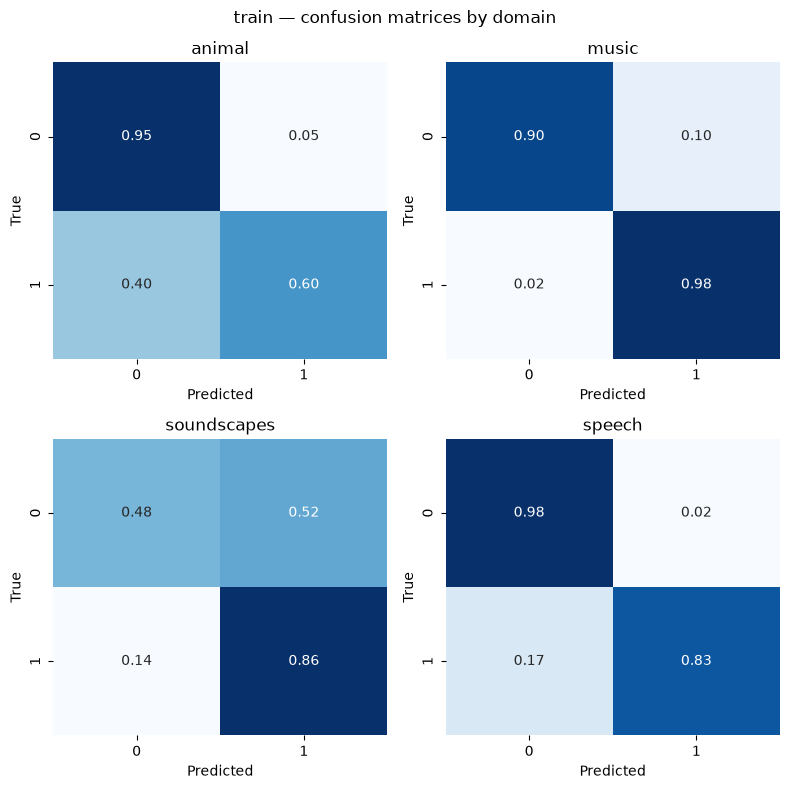

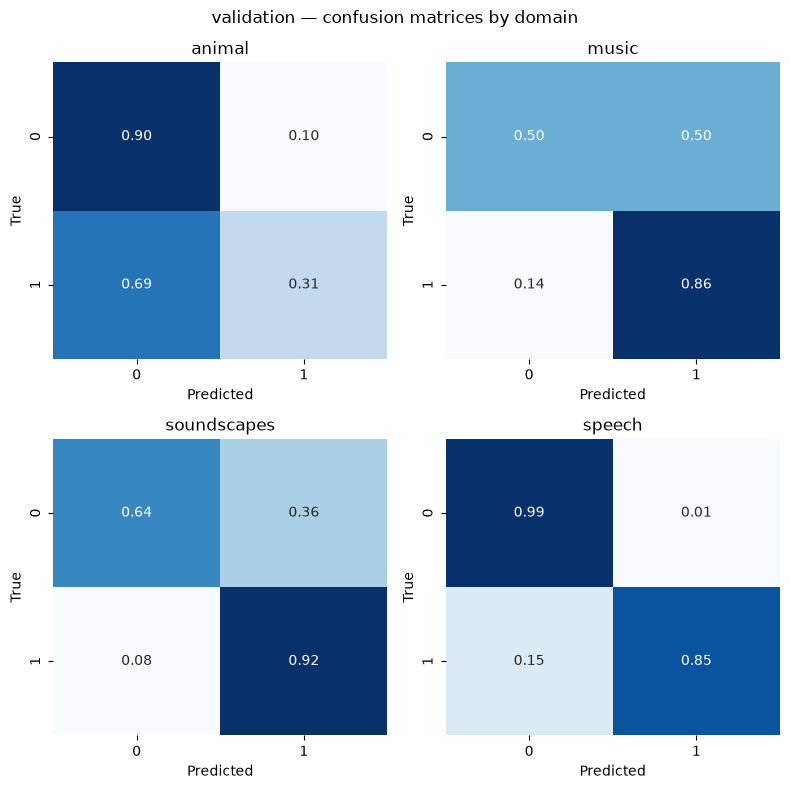

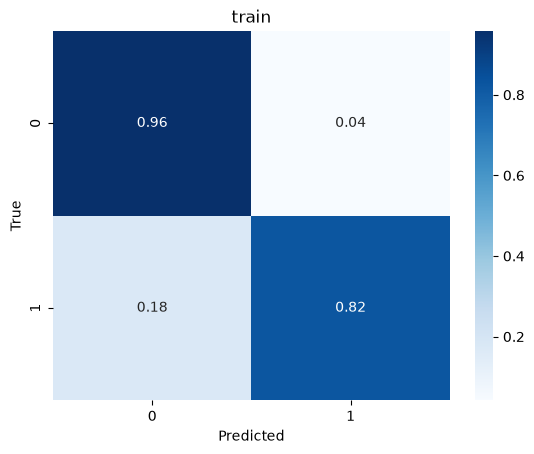

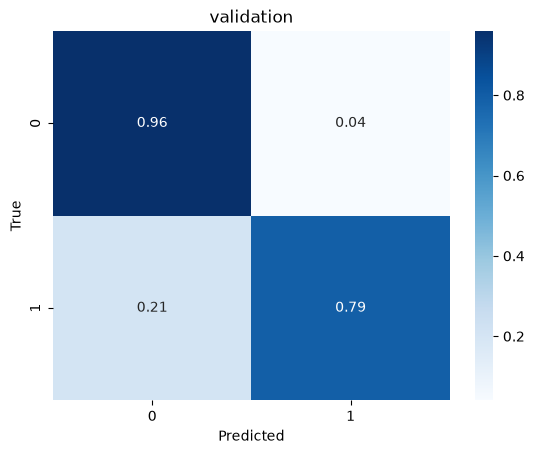

c:\Users\alice\master_thesis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alice\master_thesis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\alice\master_thesis\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0]

Confusion Matrices for frame_dann_bilstm experiment


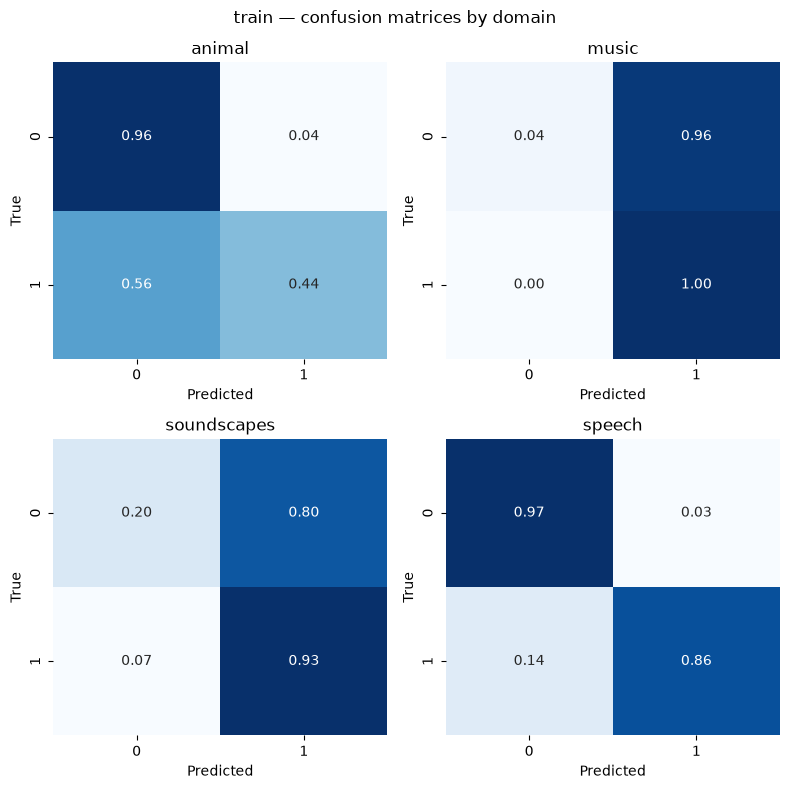

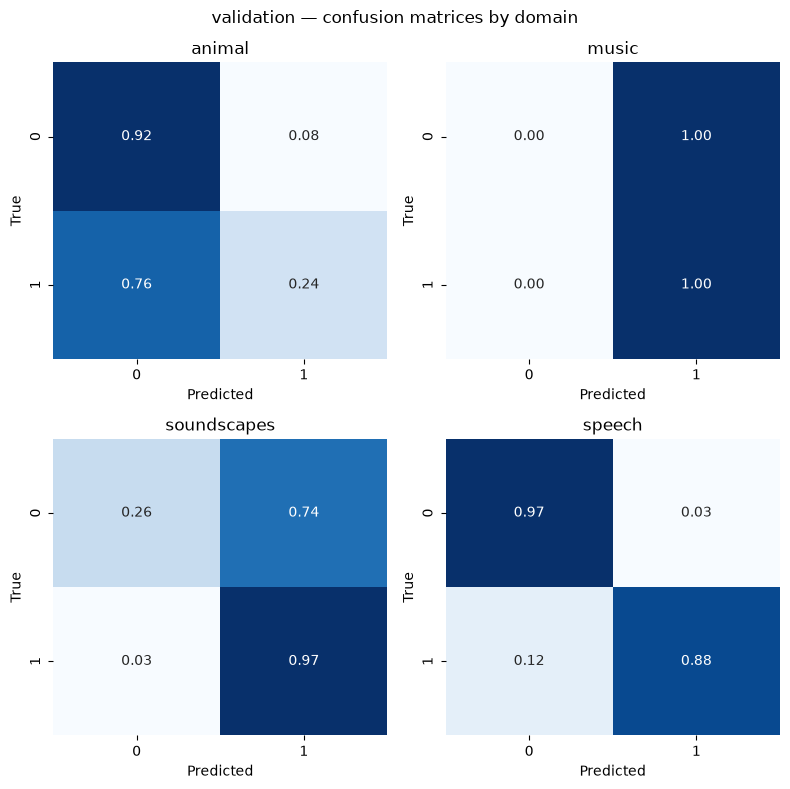

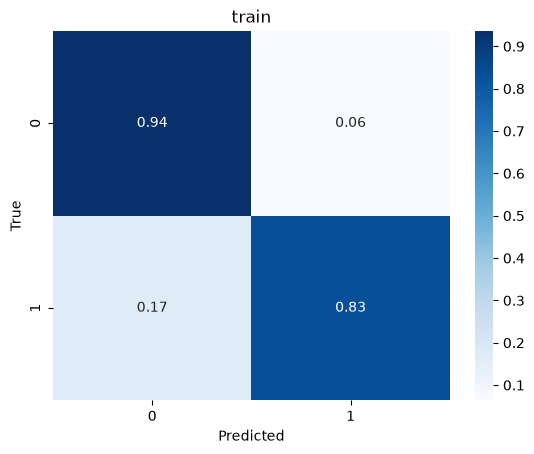

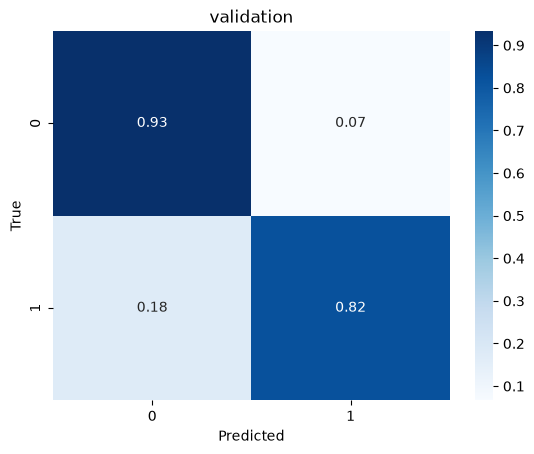

In [3]:
for run in ("frame_bilstm", "frame_dann_bilstm"):
    splits = [("train", f"{results_dict[run]}/train_results.pt"), ("validation", f"{results_dict[run]}/validation_results.pt")]

    conf_mat_outdir = os.path.join("outputs/plots/confusion_matrices", run)
    tables_outdir = os.path.join("outputs/tables", run)

    for d in (conf_mat_outdir, tables_outdir):
        os.makedirs(d, exist_ok=True)


    reports = evaluation.compute_classification_reports(None, splits)
    all_reports[run] = reports
    #display_classification_reports(reports)

    with open(f"outputs/tables/{run}/classification_reports.json", "w") as f:
        json.dump(reports, f, indent=2)

    print(f"Confusion Matrices for {run} experiment")
    for split_name, pt_path in splits:
        evaluation.save_combined_confusion_matrix(None, pt_path, split_name, output_dir=f"plots/confusion_matrices/{run}")

    evaluation.save_confusion_matrices(None, splits)

In [4]:
for split_name in ("train", "validation"):
    tables = {}
    for run in ("frame_bilstm", "frame_dann_bilstm"):
        tables[run] = evaluation.build_summary_table(all_reports[run], split_name=split_name)

    comparison = pd.concat(tables, axis=1)
    print(split_name)
    display(comparison)

train


frame_bilstm                                                 \
                accuracy balanced_accuracy precision_macro recall_macro   
domain                                                                    
animal          0.880172          0.777748        0.837392     0.777748   
music           0.954323          0.935921        0.946509     0.935921   
soundscapes     0.669763          0.669566        0.698326     0.669566   
speech          0.948690          0.906229        0.934586     0.906229   

                      frame_dann_bilstm                                    \
             f1_macro          accuracy balanced_accuracy precision_macro   
domain                                                                      
animal       0.801807          0.855582          0.704423        0.816666   
music        0.941035          0.742251          0.518293        0.869852   
soundscapes  0.657270          0.564499          0.564122        0.638003   
speech       0.919471          0.948435          0.914465        0.926941   

                                    
            recall_macro  f1_macro  
domain                              
animal          0.704423  0.738079  
music           0.518293  0.460484  
soundscapes     0.564122  0.496986  
speech          0.914465  0.920517

validation


frame_bilstm                                                 \
                accuracy balanced_accuracy precision_macro recall_macro   
domain                                                                    
animal          0.761905          0.605613        0.649532     0.605613   
music           0.766234          0.679825        0.693032     0.679825   
soundscapes     0.778689          0.778689        0.802156     0.778689   
speech          0.960143          0.921215        0.955502     0.921215   

                      frame_dann_bilstm                                    \
             f1_macro          accuracy balanced_accuracy precision_macro   
domain                                                                      
animal       0.616409          0.761905          0.582203        0.642524   
music        0.685572          0.740260          0.500000        0.370130   
soundscapes  0.774306          0.614754          0.614754        0.728098   
speech       0.937069          0.955544          0.929223        0.934791   

                                    
            recall_macro  f1_macro  
domain                              
animal          0.582203  0.589908  
music           0.500000  0.425373  
soundscapes     0.614754  0.560107  
speech          0.929223  0.931971

FRAME_BILSTM


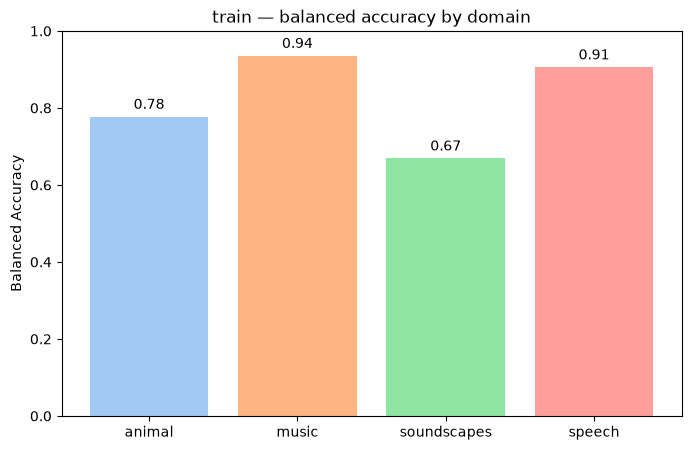

FRAME_BILSTM


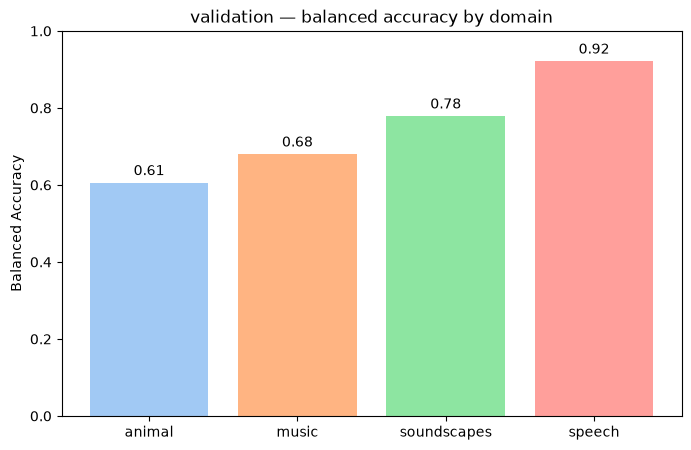

FRAME_DANN_BILSTM


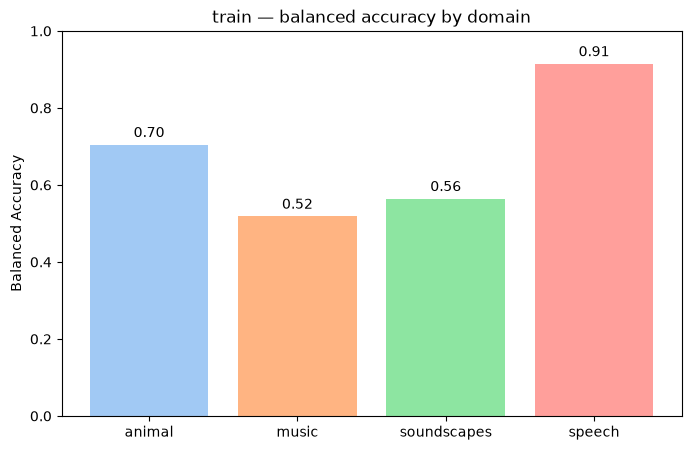

FRAME_DANN_BILSTM


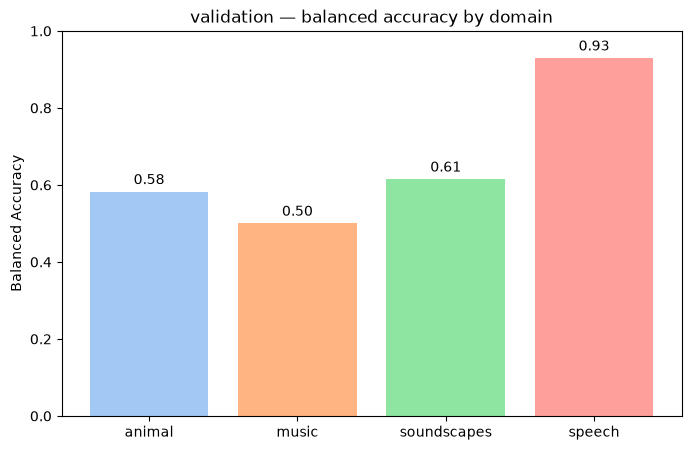

In [5]:
for run in ("frame_bilstm", "frame_dann_bilstm"):
    for split_name in ("train", "validation"):
        print(f"{run.upper()}")
        evaluation.plot_domain_metric_bar(all_reports[run], split_name=split_name, metric="balanced_accuracy", filename=f"plots/{run}/{split_name}_domain_summary.png")

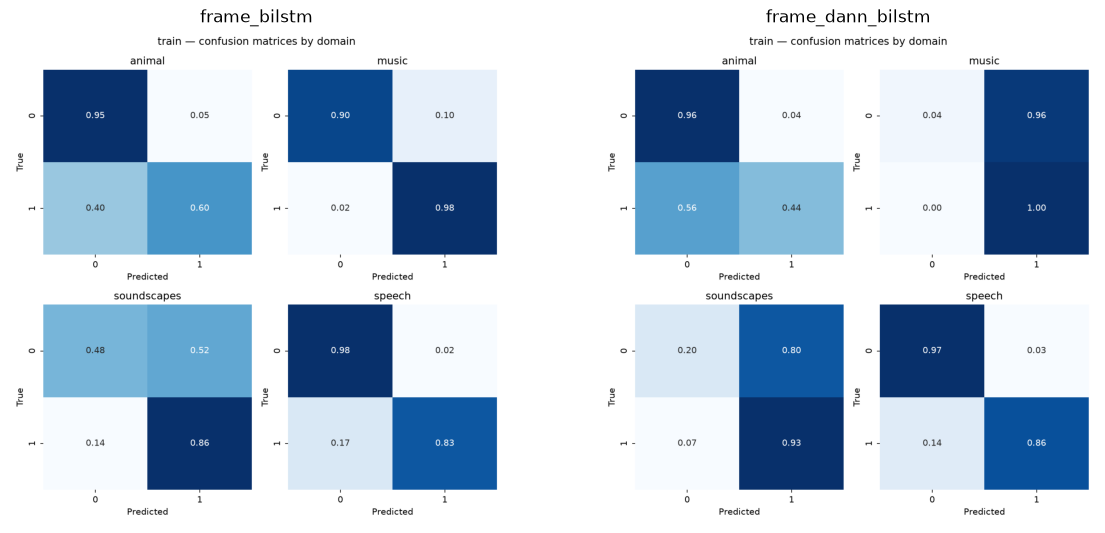

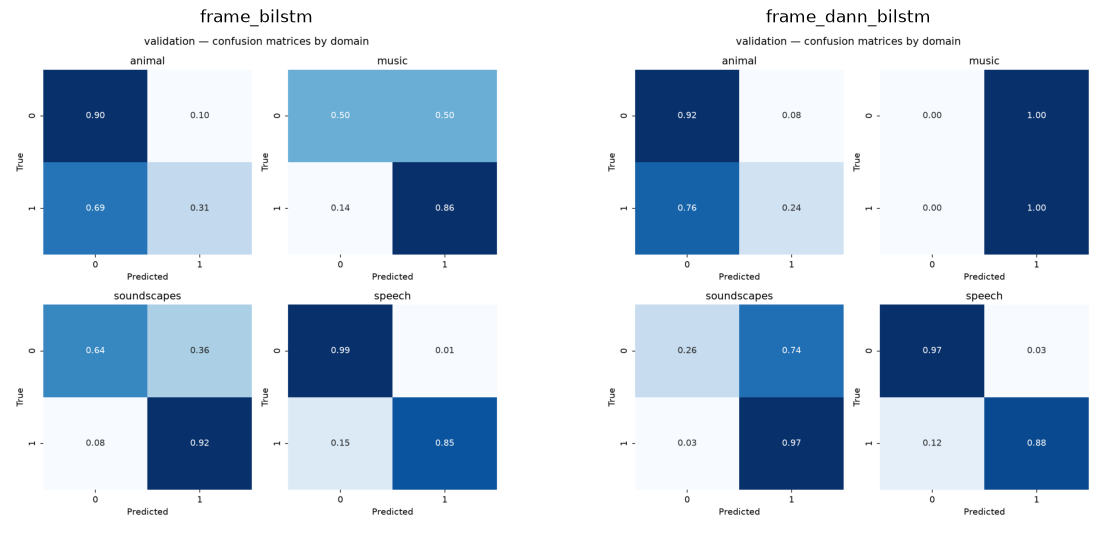

In [6]:
for split_name in ("train", "validation"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, run in zip(axes, ("frame_bilstm", "frame_dann_bilstm")):
        img = mpimg.imread(f"outputs/plots/confusion_matrices/{run}/{split_name}_combined_cf_matrix.png")
        ax.imshow(img)
        ax.set_title(run)
        ax.axis("off")
    plt.show()